In [1]:
#!pip3 install matplotlib pandas ipykernel
import matplotlib.pyplot as pl
import pandas as pd

In [2]:
df = pd.read_csv('iphone-dimensions/data/iphones.csv')
df.head(7)

,id,product_id,state,name,also_known_as,family,announced,released,height_mm,width_mm,...,display_in,resolution_width_px,resolution_height_px,ppi,url,source_url,dates_source_url,model_identifiers,model_numbers,model_identifiers_source
0,iphone-duo,iphone-duo,closed,iPhone Duo,iPhone Duo (closed),iPhone Duo,2026-09-09,2026-10-23,117.8,84.1,...,5.4,1398,2034,460,https://iphonesize.com/iphone-duo,https://www.apple.com/iphone-duo/specs/,https://www.apple.com/newsroom/2026/09/apple-u...,"iPhone19,4",A3447 | A3719 | A3720 | A3721,secondary
1,iphone-duo-unfolded,iphone-duo,open,iPhone Duo,iPhone Duo (open),iPhone Duo,2026-09-09,2026-10-23,117.8,164.6,...,7.6,1878,2670,430,https://iphonesize.com/iphone-duo?duo=unfolded,https://www.apple.com/iphone-duo/specs/,https://www.apple.com/newsroom/2026/09/apple-u...,"iPhone19,4",A3447 | A3719 | A3720 | A3721,secondary
2,iphone-18-pro-max,iphone-18-pro-max,NaN,iPhone 18 Pro Max,NaN,iPhone 18,2026-09-09,2026-09-18,163.4,78.0,...,6.9,1320,2868,460,https://iphonesize.com/iphone-18-pro-max,https://www.apple.com/iphone-18-pro/specs/,https://www.apple.com/newsroom/2026/09/apple-d...,"iPhone19,3 | iPhone19,7",A3473 | A3716 | A3718 | A3717,apple
3,iphone-18-pro,iphone-18-pro,NaN,iPhone 18 Pro,NaN,iPhone 18,2026-09-09,2026-09-18,150.0,71.9,...,6.3,1206,2622,460,https://iphonesize.com/iphone-18-pro,https://www.apple.com/iphone-18-pro/specs/,https://www.apple.com/newsroom/2026/09/apple-d...,"iPhone19,2",A3472 | A3713 | A3715 | A3714,apple
4,iphone-17-pro-max,iphone-17-pro-max,NaN,iPhone 17 Pro Max,NaN,iPhone 17,2025-09-09,2025-09-19,163.4,78.0,...,6.9,1320,2868,460,https://iphonesize.com/iphone-17-pro-max,https://support.apple.com/en-us/125091,https://www.apple.com/newsroom/2025/09/apple-u...,"iPhone18,2",A3257 | A3525 | A3527 | A3526,apple
5,iphone-17-pro,iphone-17-pro,NaN,iPhone 17 Pro,NaN,iPhone 17,2025-09-09,2025-09-19,150.0,71.9,...,6.3,1206,2622,460,https://iphonesize.com/iphone-17-pro,https://support.apple.com/en-us/125090,https://www.apple.com/newsroom/2025/09/apple-u...,"iPhone18,1",A3256 | A3522 | A3524 | A3523,apple
6,iphone-17-air,iphone-17-air,NaN,iPhone Air,iPhone 17 Air,iPhone 17,2025-09-09,2025-09-19,156.2,74.7,...,6.5,1260,2736,460,https://iphonesize.com/iphone-17-air,https://support.apple.com/en-us/125092,https://www.apple.com/newsroom/2025/09/introdu...,"iPhone18,4",A3260 | A3516 | A3518 | A3517,apple


In [3]:
sufx = df['name'].str.split(' ').str[-1]
# parse name by suffix out of fixed list (duo, max, pro) into classes   
classes = []
for suf in sufx:
    match suf:
        case 'Max':
            classes.append('Max')
        case 'Pro':
            classes.append('Pro')
        case 'Duo':
            classes.append('Duo')
        case 'Plus':
            classes.append('Plus')
        case 'mini':
            classes.append('Mini')
        case _:
            classes.append('Standard')
df['class'] = classes
df['year'] = df['released'].str.split('-').str[0].astype(int)
df.head(10)

,id,product_id,state,name,also_known_as,family,announced,released,height_mm,width_mm,...,resolution_height_px,ppi,url,source_url,dates_source_url,model_identifiers,model_numbers,model_identifiers_source,class,year
0,iphone-duo,iphone-duo,closed,iPhone Duo,iPhone Duo (closed),iPhone Duo,2026-09-09,2026-10-23,117.8,84.1,...,2034,460,https://iphonesize.com/iphone-duo,https://www.apple.com/iphone-duo/specs/,https://www.apple.com/newsroom/2026/09/apple-u...,"iPhone19,4",A3447 | A3719 | A3720 | A3721,secondary,Duo,2026
1,iphone-duo-unfolded,iphone-duo,open,iPhone Duo,iPhone Duo (open),iPhone Duo,2026-09-09,2026-10-23,117.8,164.6,...,2670,430,https://iphonesize.com/iphone-duo?duo=unfolded,https://www.apple.com/iphone-duo/specs/,https://www.apple.com/newsroom/2026/09/apple-u...,"iPhone19,4",A3447 | A3719 | A3720 | A3721,secondary,Duo,2026
2,iphone-18-pro-max,iphone-18-pro-max,NaN,iPhone 18 Pro Max,NaN,iPhone 18,2026-09-09,2026-09-18,163.4,78.0,...,2868,460,https://iphonesize.com/iphone-18-pro-max,https://www.apple.com/iphone-18-pro/specs/,https://www.apple.com/newsroom/2026/09/apple-d...,"iPhone19,3 | iPhone19,7",A3473 | A3716 | A3718 | A3717,apple,Max,2026
3,iphone-18-pro,iphone-18-pro,NaN,iPhone 18 Pro,NaN,iPhone 18,2026-09-09,2026-09-18,150.0,71.9,...,2622,460,https://iphonesize.com/iphone-18-pro,https://www.apple.com/iphone-18-pro/specs/,https://www.apple.com/newsroom/2026/09/apple-d...,"iPhone19,2",A3472 | A3713 | A3715 | A3714,apple,Pro,2026
4,iphone-17-pro-max,iphone-17-pro-max,NaN,iPhone 17 Pro Max,NaN,iPhone 17,2025-09-09,2025-09-19,163.4,78.0,...,2868,460,https://iphonesize.com/iphone-17-pro-max,https://support.apple.com/en-us/125091,https://www.apple.com/newsroom/2025/09/apple-u...,"iPhone18,2",A3257 | A3525 | A3527 | A3526,apple,Max,2025
5,iphone-17-pro,iphone-17-pro,NaN,iPhone 17 Pro,NaN,iPhone 17,2025-09-09,2025-09-19,150.0,71.9,...,2622,460,https://iphonesize.com/iphone-17-pro,https://support.apple.com/en-us/125090,https://www.apple.com/newsroom/2025/09/apple-u...,"iPhone18,1",A3256 | A3522 | A3524 | A3523,apple,Pro,2025
6,iphone-17-air,iphone-17-air,NaN,iPhone Air,iPhone 17 Air,iPhone 17,2025-09-09,2025-09-19,156.2,74.7,...,2736,460,https://iphonesize.com/iphone-17-air,https://support.apple.com/en-us/125092,https://www.apple.com/newsroom/2025/09/introdu...,"iPhone18,4",A3260 | A3516 | A3518 | A3517,apple,Standard,2025
7,iphone-17,iphone-17,NaN,iPhone 17,NaN,iPhone 17,2025-09-09,2025-09-19,149.6,71.5,...,2622,460,https://iphonesize.com/iphone-17,https://support.apple.com/en-us/125089,https://www.apple.com/newsroom/2025/09/apple-d...,"iPhone18,3",A3258 | A3519 | A3521 | A3520,apple,Standard,2025
8,iphone-17e,iphone-17e,NaN,iPhone 17e,NaN,iPhone 17,2026-03-02,2026-03-11,146.7,71.5,...,2532,460,https://iphonesize.com/iphone-17e,https://support.apple.com/en-us/126470,https://www.apple.com/newsroom/2026/03/apple-i...,"iPhone18,5",A3575 | A3635 | A3634,apple,Standard,2026
9,iphone-16-pro-max,iphone-16-pro-max,NaN,iPhone 16 Pro Max,NaN,iPhone 16,2024-09-09,2024-09-20,163.0,77.6,...,2868,460,https://iphonesize.com/iphone-16-pro-max,https://support.apple.com/en-us/121032,https://www.apple.com/newsroom/2024/09/apple-d...,"iPhone17,2",A3084 | A3295 | A3297 | A3296,apple,Max,2024


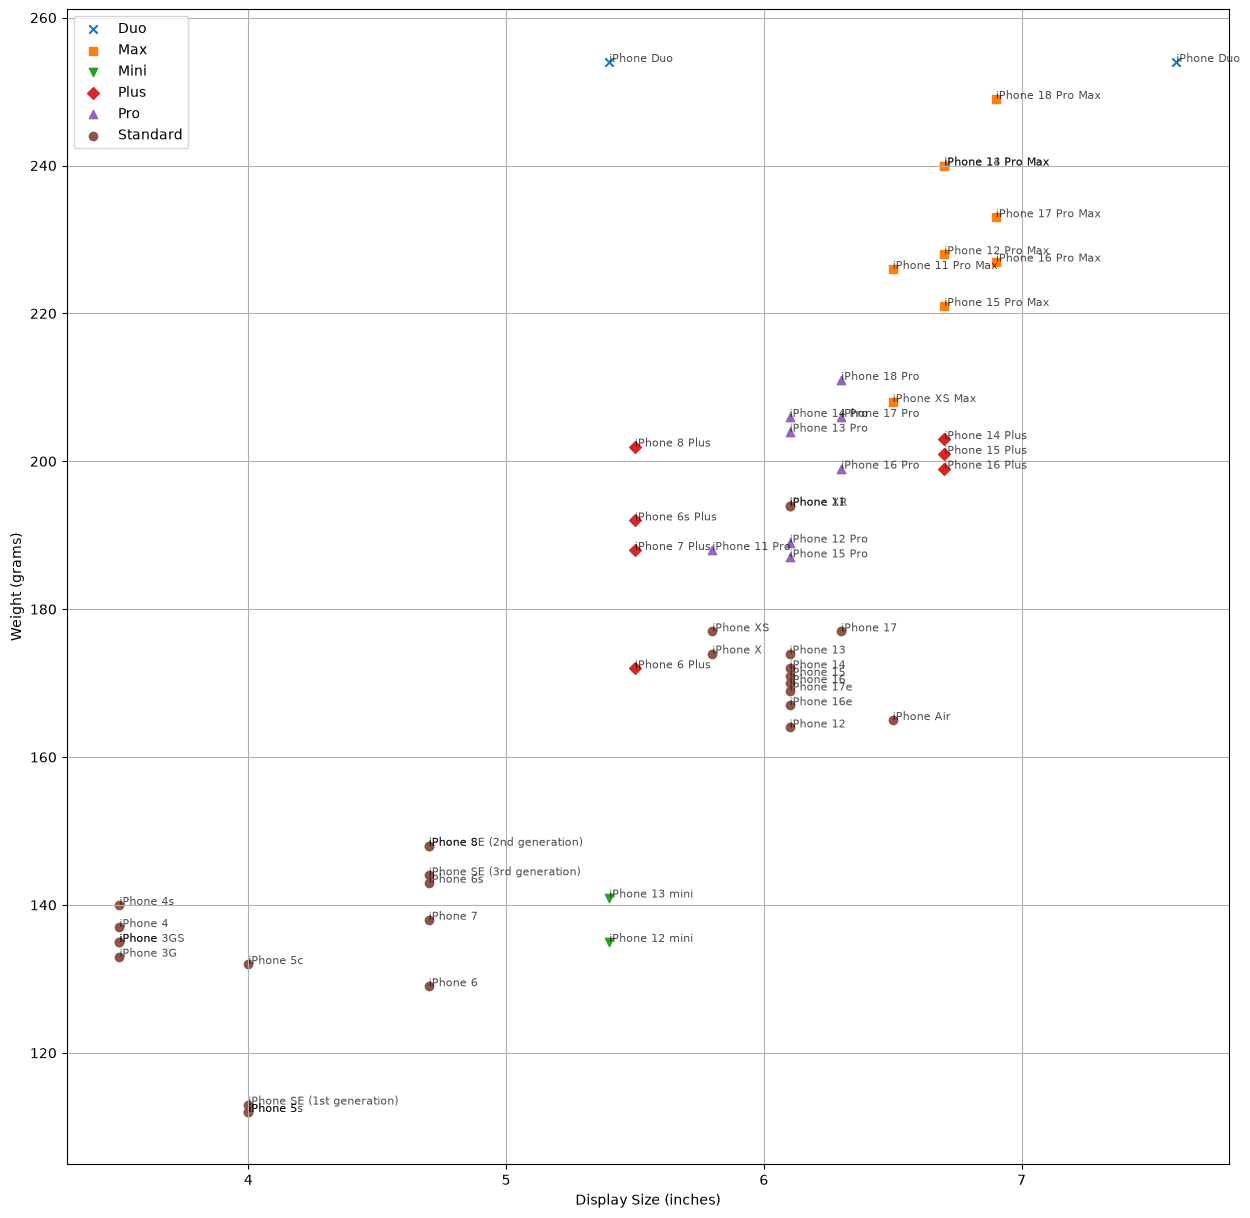

In [7]:
fig, ax = pl.subplots(figsize=(15, 15))
# plot weight vs display size using different marker symbols for classes
clsmrk = {'Standard': 'o', 'Max': 's', 'Pro': '^', 'Duo': 'x', 'Plus': 'D', 'Mini': 'v'}
for cls, d in df.groupby('class'):
    #pl.scatter(d['display_in'], d['weight_g'], c=d['year'], marker=clsmrk[cls], label=cls)
    pl.scatter(d['display_in'], d['weight_g'], marker=clsmrk[cls], label=cls)

# add name as label to each point
for i, row in df.iterrows():
    pl.annotate(row['name'], (row['display_in'], row['weight_g']), fontsize=8, alpha=0.7)   

pl.legend()
ax.set_xlabel('Display Size (inches)')
ax.set_ylabel('Weight (grams)')
ax.grid()